# CROTTC-IF versus wav2vec2 B: frozen exploratory pilot

All cells read existing outputs; no model inference, APIs, training or threshold tuning. The user recordings have no expert phone labels.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image, Audio
ROOT = Path.cwd().resolve()
while not (ROOT / "scripts/report_crottc.py").is_file():
    if ROOT.parent == ROOT: raise RuntimeError("Open from the MDD workspace")
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
from scripts.report_crottc import load_bundle, research_rows, ui_rows, case_rows
OUT = ROOT / 'data/generated/crottc-pilot-20261023'
bundle = load_bundle(OUT)
manifest, results = bundle["manifest"], bundle["results"]
display({"status": results["status"], "manifest_sha256": results["manifest_sha256"], "expert_paired_cases": results["summary"]["paired_completed_expert_cases"]})

{'status': 'completed',
 'manifest_sha256': '34f9c65701614c2891e85f7a9dc7dffeaaa8775d9fac310d36d761423c9ba8f1',
 'expert_paired_cases': 24}

In [2]:
display(Markdown("## Selection: fixed before inference"))
display(manifest["selection"])
display(pd.DataFrame([{key: case.get(key) for key in ("id", "speaker_id", "group", "stratum", "manual_error_density", "duration_sec")} for case in manifest["cases"]]))

## Selection: fixed before inference

{'test_cases': 24,
 'speakers': ['NJS', 'TLV', 'TNI', 'TXHC', 'YKWK', 'ZHAA'],
 'stratification': 'Within each of six test speakers, sort by expert error-event density; split in halves; select two per half using SHA256(crottc-pilot-v1\\nID). No outputs or thresholds used.',
 'sampling_limitation': 'Small label-stratified exploratory pilot, not an unbiased full-test or speaker-population estimate.',
 'training_validation_ids_overlap': [],
 'test_used_for_tuning': False}

,id,speaker_id,group,stratum,manual_error_density,duration_sec
0,NJS-arctic_a0097,NJS,expert_test_pilot,upper_error_density_half,0.266667,4.080000
1,NJS-arctic_a0111,NJS,expert_test_pilot,lower_error_density_half,0.102564,4.131451
2,NJS-arctic_a0113,NJS,expert_test_pilot,upper_error_density_half,0.285714,3.100975
3,NJS-arctic_a0123,NJS,expert_test_pilot,lower_error_density_half,0.074074,2.425057
4,TLV-arctic_a0040,TLV,expert_test_pilot,lower_error_density_half,0.206897,3.980000
5,TLV-arctic_a0100,TLV,expert_test_pilot,lower_error_density_half,0.200000,2.400000
6,TLV-arctic_b0358,TLV,expert_test_pilot,upper_error_density_half,0.294118,6.059410
7,TLV-arctic_b0481,TLV,expert_test_pilot,upper_error_density_half,0.428571,3.200000
8,TNI-arctic_a0021,TNI,expert_test_pilot,upper_error_density_half,0.166667,3.270000
9,TNI-arctic_a0098,TNI,expert_test_pilot,lower_error_density_half,0.100000,1.360000


## Raw and shared-inventory research scores

,model,inventory,UTTERANCES,TA,FR,FA,TR,CD,DE,DIAG_EXCLUDED,PER_S,PER_D,PER_I,PER_N,WORD_TP,WORD_FP,WORD_FN,WORD_TN,WORD_SCORED_UTTERANCES,WORD_UNMAPPED_EVENTS,precision,recall,f1,far,frr,der,per,word_precision,word_recall,word_f1
0,cascade-B,raw,24,645,73,70,70,38,30,2,105,29,19,819,66,28,34,100,24,0,0.489510,0.500000,0.494700,0.500000,0.101671,0.441176,0.186813,0.702128,0.66,0.680412
1,cascade-B,shared_inventory,24,646,72,70,70,41,27,2,100,29,19,819,66,28,34,100,24,0,0.492958,0.500000,0.496454,0.500000,0.100279,0.397059,0.180708,0.702128,0.66,0.680412
2,crottc-if,raw,24,680,374,86,54,22,32,0,67,3,370,819,84,60,16,68,24,0,0.126168,0.385714,0.190141,0.614286,0.354839,0.592593,0.537241,0.583333,0.84,0.688525
3,crottc-if,shared_inventory,24,680,374,86,54,24,30,0,62,3,370,819,84,60,16,68,24,0,0.126168,0.385714,0.190141,0.614286,0.354839,0.555556,0.531136,0.583333,0.84,0.688525


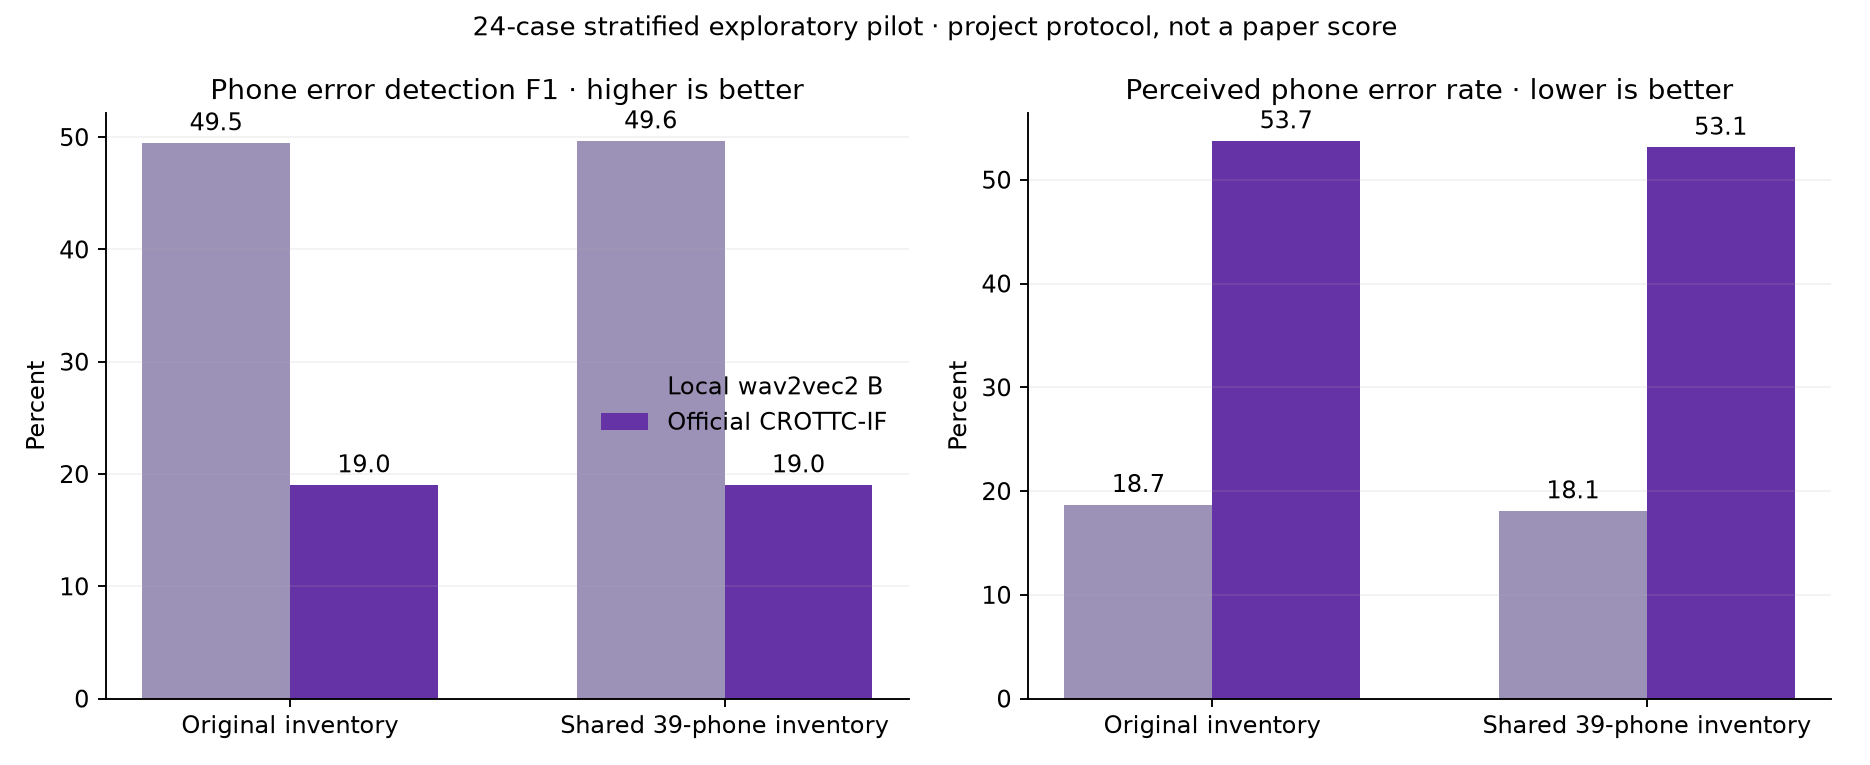

In [3]:
display(Markdown("## Raw and shared-inventory research scores"))
with pd.option_context("display.max_columns", None): display(pd.DataFrame(research_rows(bundle)))
display(Image(filename=str(OUT / "research_metrics.png")))

In [4]:
display(Markdown("## Actual optional UI review hints, separately from calibrated decisions"))
with pd.option_context("display.max_columns", None): display(pd.DataFrame(ui_rows(bundle)))
display(Markdown("An absent review hint is not expert acceptance. Unavailable assessments and calibrated abstentions remain explicit. These are exploratory word-index review-list counts, not the research phone F1."))

## Actual optional UI review hints, separately from calibrated decisions

,model,reference_words,gold_error_words,review_available_words,unavailable_words,hint_tp,hint_fp,hint_fn,not_flagged_gold_correct,calibrated_decided_words,hint_precision,hint_recall,hint_f1,hint_false_positive_rate,review_coverage,inference_sec
0,cascade-B,228,100,228,0,63,22,37,106,0,0.741176,0.63,0.681081,0.171875,1.0,9.408
1,crottc-if,228,100,228,0,82,55,18,73,0,0.598540,0.82,0.691983,0.429688,1.0,106.233


An absent review hint is not expert acceptance. Unavailable assessments and calibrated abstentions remain explicit. These are exploratory word-index review-list counts, not the research phone F1.

In [5]:
per_case = pd.DataFrame(case_rows(bundle))
display(Markdown("## All 54 model/case outputs"))
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None): display(per_case)

## All 54 model/case outputs

,id,speaker,group,stratum,reference_text,model,status,error,canonical,expert_perceived,predicted,decoded_labels,raw_f1,raw_per,shared_f1,shared_per,inference_sec,review_status,review_reason,review_words,calibrated,audio_sha256
0,NJS-arctic_a0097,NJS,expert_test_pilot,upper_error_density_half,Then you can arrange yourself comfortably among these robes in the bow,cascade-B,completed,None,DH EH N Y UW K AH N ER EY N JH Y ER S EH L F K AH M F ER T AH B L IY AH M AH N DH IY Z R OW B Z IH N DH AH B OW,D EH NG Y UW K AH N ER EY N CH Y ER S EH L F K AO M F ER T AH B L IY AH M AO NG D IY Z R AO B S IY N D AH B AW,DH EH N Y UW AE N ER EY N JH Y ER S EH F K AH M F T AH B L IY AH M AO NG D IY Z B R AO B P S IH N D AH B AW,,0.560000,0.244444,0.560000,0.244444,0.782,available,tentative_differences,"can, yourself, comfortably, among, these, robes, the",False,26e787fe1eb7a71d7c976d738f01292b234bf02bd6219e5e517bac3c6bc4000d
1,NJS-arctic_a0097,NJS,expert_test_pilot,upper_error_density_half,Then you can arrange yourself comfortably among these robes in the bow,crottc-if,completed,None,DH EH N Y UW K AH N ER EY N JH Y ER S EH L F K AH M F ER T AH B L IY AH M AH N DH IY Z R OW B Z IH N DH AH B OW,D EH NG Y UW K AH N ER EY N CH Y ER S EH L F K AO M F ER T AH B L IY AH M AO NG D IY Z R AO B S IY N D AH B AW,D EH N Y UW K AE N ER EY N JH Y UH ER S R S EH L F K AO M F ER T AH B AH L IY AH M AO OW AO N NG N D IY Z S R OW AO OW AO B S IY IH N D AH B AW,sil d eh n y uw k ae n er ey n jh y uh er s r s eh l f sil k ao m f er t ah b ah l iy sil ah m ao ow ao n ng n d iy z s r ow ao ow ao b s sil iy ih n d ah b aw sil,0.424242,0.355556,0.424242,0.355556,4.813,available,tentative_differences,"Then, yourself, comfortably, among, these, robes, the",False,26e787fe1eb7a71d7c976d738f01292b234bf02bd6219e5e517bac3c6bc4000d
2,NJS-arctic_a0111,NJS,expert_test_pilot,lower_error_density_half,Instead he joined her and they ate like two hungry children,cascade-B,completed,None,IH N S T EH D HH IY JH OY N D HH ER AE N D DH EY EY T L AY K T UW HH AH NG G R IY CH IH L D R AH N,IY NG S T EH D HH IY JH OY N D HH ER AE N D D EY EY T L AY K T UW HH AH NG G R IY CH IY L D R AH N,IH N S T EH D HH IY JH OY N D HH ER AE N D EY EY T L AY K T UW HH AH NG G R IY CH IH D R AH N,,0.333333,0.128205,0.333333,0.128205,0.406,available,tentative_differences,"they, children",False,9aed7263eeec1358f9d999b1bbfd2b5a25d29d1398268e1b177f20bc6849b67a
3,NJS-arctic_a0111,NJS,expert_test_pilot,lower_error_density_half,Instead he joined her and they ate like two hungry children,crottc-if,completed,None,IH N S T EH D HH IY JH OY N D HH ER AE N D DH EY EY T L AY K T UW HH AH NG G R IY CH IH L D R AH N,IY NG S T EH D HH IY JH OY N D HH ER AE N D D EY EY T L AY K T UW HH AH NG G R IY CH IY L D R AH N,IY IH N S T EH T EH D EH D HH IY JH OY N D HH ER AE AE EH N D EY IY EY EY EY EY T EY T L AY K T UW HH AH NG G R IY CH IH L D R AH N,sil iy ih n s t eh t eh d eh d sil hh iy jh oy n d hh er sil ae sil ae eh n d ey iy ey sil ey sil ey sil ey t ey t l ay k t uw hh ah ng g r iy ch ih l d r ah n sil,0.117647,0.384615,0.117647,0.384615,4.437,available,tentative_differences,"Instead, her, and, they",False,9aed7263eeec1358f9d999b1bbfd2b5a25d29d1398268e1b177f20bc6849b67a
4,NJS-arctic_a0113,NJS,expert_test_pilot,upper_error_density_half,I suppose you picked that lingo up among the Indians,cascade-B,completed,None,AY S AH P OW Z Y UW P IH K T DH AE T L IH NG G OW AH P AH M AH NG DH AH IH N D IY AH N Z,AY S AH P AO S Y UW P IH K T D AE T L IH NG G OW AO P AH M AO N D EH IY N D IY AH N S,AY S UW P OW Z Y UW P IH K D AE T L NG G OW AH AH M AO NG D IH IH N D IY AH N S,,0.526316,0.285714,0.526316,0.285714,0.297,available,tentative_differences,"suppose, picked, that, lingo, up, among, the, Indians",False,5e455698116994dfb0ffd8b640857a38283eb365f4d9f83ee48d498d61bee3e3
5,NJS-arctic_a0113,NJS,expert_test_pilot,upper_error_density_half,I suppose you picked that lingo up among the Indians,crottc-if,completed,None,AY S AH P OW Z Y U

In [6]:
display(Markdown("## Listen to three deterministic examples"))
examples = [manifest["cases"][0], manifest["cases"][4], next(case for case in manifest["cases"] if case["id"] == "user-road")]
for case in examples:
    display(Markdown(f"### {case['id']}\n**Intended text:** {case['reference_text']}"))
    display(Audio(filename=str(ROOT / case["audio"]), embed=True))
    display(per_case.loc[per_case.id == case["id"], ["model", "expert_perceived", "predicted", "review_words", "raw_f1", "shared_f1", "inference_sec"]])

## Listen to three deterministic examples

### NJS-arctic_a0097
**Intended text:** Then you can arrange yourself comfortably among these robes in the bow

,model,expert_perceived,predicted,review_words,raw_f1,shared_f1,inference_sec
0,cascade-B,D EH NG Y UW K AH N ER EY N CH Y ER S EH L F K...,DH EH N Y UW AE N ER EY N JH Y ER S EH F K AH ...,"can, yourself, comfortably, among, these, robe...",0.560000,0.560000,0.782
1,crottc-if,D EH NG Y UW K AH N ER EY N CH Y ER S EH L F K...,D EH N Y UW K AE N ER EY N JH Y UH ER S R S EH...,"Then, yourself, comfortably, among, these, rob...",0.424242,0.424242,4.813


### TLV-arctic_a0040
**Intended text:** I suppose you wonder why she is coming up here

,model,expert_perceived,predicted,review_words,raw_f1,shared_f1,inference_sec
8,cascade-B,AY S AH P OW T UW Y UW W AH N D AH W AY S IY I...,AY S AH P OW T UW Y UW W AO N D ER W AY S IY K...,"suppose, wonder, she, is",0.50,0.50,0.765
9,crottc-if,AY S AH P OW T UW Y UW W AH N D AH W AY S IY I...,AY S AH P OW UW T T Y UW Y Y UW W AO N D AH W ...,"suppose, wonder, why, she, is, coming",0.32,0.32,3.938


### user-road
**Intended text:** End of the road for some players

,model,expert_perceived,predicted,review_words,raw_f1,shared_f1,inference_sec
50,cascade-B,None,AH N D OW DH EH L OW D AH F AO R S AA M OW N P...,"End, of, the, road, for, some, players",NaN,NaN,0.359
51,crottc-if,None,AE AE AE N D N D OW D OW AO OW AO DH D DH EH E...,"End, of, the, road, for, some, players",NaN,NaN,4.313


In [7]:
display(Markdown("## User recordings: development outputs, no expert accuracy claims"))
with pd.option_context("display.max_colwidth", None, "display.max_columns", None): display(per_case.loc[per_case.group == "user_development"])
display(Markdown("Intended text does not identify which sounds were actually mispronounced. Human phone/error labels would be needed to score these recordings."))

## User recordings: development outputs, no expert accuracy claims

,id,speaker,group,stratum,reference_text,model,status,error,canonical,expert_perceived,predicted,decoded_labels,raw_f1,raw_per,shared_f1,shared_per,inference_sec,review_status,review_reason,review_words,calibrated,audio_sha256
48,user-stella,unverified_user_recording,user_development,None,"Please call Stella. Ask her to bring these things with her from the store: Six spoons of fresh snow peas, five thick slabs of blue cheese, and maybe a snack for her brother Bob. We also need a small plastic snake and a big toy frog for the kids. She can scoop these things into three red bags, and we will go meet her Wednesday at the train station.",cascade-B,completed,None,None,None,B L IY K OW S EH L AH AA S HH AH T AH B R IH NG V IY TH IH NG S Z W IH TH HH AH F R AH M AH S T AO S IH K S B UW N AH V F R EH SH N OW B IY S F AY T IH K S L AE P AH V L UW SH IY S AE D M EY B IY AH S N EH K F AO HH AH B R AA DH AH B AO OW AH AO S OW N IY D AH V S M AO B L AE S IH K S N EH AE AH B IH G T OY F R AO F AO DH AH K IY S SH IY K IY AE S K UW L IY TH IH NG S Z IH N T UW T R IY R EH D B AE Z AE N W IH L G OW M IY HH AH W EH N Z D EY AH DH AH S T R EY N Z T EY SH AH N,,NaN,NaN,NaN,NaN,2.688,available,tentative_differences,"Please, call, Stella., Ask, her, these, things, her, the, store:, Six, spoons, snow, peas,, five, thick, slabs, blue, cheese,, and, snack, for, her, brother, Bob., We, also, small, plastic, snake, and, frog, for, kids., can, scoop, these, things, three, bags,, and, we, meet, her, at, train, station.",False,2d33843f2da479dccab7fa364c02745da675a32fb1f76004810c001e7e507d18
49,user-stella,unverified_user_recording,user_development,None,"Please call Stella. Ask her to bring these things with her from the store: Six spoons of fresh snow peas, five thick slabs of blue cheese, and maybe a snack for her brother Bob. We also need a small plastic snake and a big toy frog for the kids. She can scoop these things into three red bags, and we will go meet her Wednesday at the train station.",crottc-if,completed,None,None,None,S P B P L IY K OW AO OW AO W S EH S EH L AH AH AA AE S HH UH AH T UW B R IY NG DH D DH IY TH IY TH HH TH IH IY IH NG S Z S W IH T D HH UH AH UH AH F R AO AH M AH S T S T AO T AO AH AO AH S S IH K S P UW P UW N UW N AH V F R EH SH EH SH N OW B OW B IY B IY S IY S Z S S F F AY F AY S AY S D S T IH T IH K IH K S L S L AE P AE P AH B L UW CH SH CH IY S IY S S S AE AE EH N M N M EY B IY AH IY AH S AH S N AE EH AE EH K F K F AO AH HH AH HH UH AH UH AH B R AA D AH B AH B AO B AO OW AO S W W W Y IY AO S OW S OW N IY N IY D IY D D AH AH S M S M AO M AO W P L AE L AE S AE S T S IH K IH K S N EH K K AE AE N NG AH B IH G K T CH T CH OY AO OY F R AO K F AO F AO DH D AH K IY K IY S AA AA AA AA SH IY K IY K AE N S K UW K UW P P D L IY TH IY TH HH TH IH IY IH NG S Z S IH N T UW T UW T R IY R IY IY R EH D T B AE G AE G S Z S AE AE N AE N W IY W IY W IH G OW G OW M IY T HH AH UH AH AH W W EH N Z D EY EY W AH AE AH T DH AH S T R EY EH EY N S T EY SH AH N,sil s sil p b p l iy k ow ao ow ao w s eh s eh l ah sil ah sil aa ae s hh uh ah t uw b r iy ng dh d dh iy th iy th hh th ih iy ih ng s z s w ih t d hh uh ah uh ah f r ao ah m ah s t s t ao t ao ah ao sil ah sil s sil s ih k s p uw p uw n uw n sil ah v f r eh sh eh sh n ow b ow b iy b iy s iy s z s sil s sil f sil f ay f ay s ay s d s t ih t ih k ih k s l s l ae p ae p sil ah b l uw ch sh ch iy s iy s sil s sil s sil ae sil ae eh n m n m ey b iy ah iy ah s ah s n ae eh ae eh k f k f ao ah hh ah hh uh ah uh ah b r aa d ah b ah b ao b ao ow ao sil s sil w sil w sil w y iy ao s ow s ow n iy n iy d iy d sil d sil ah sil ah s m s m ao m ao w p l ae l ae s ae s t s ih k ih k s n eh k sil k sil ae sil ae n ng ah b ih g k t ch t ch oy ao oy f r ao k f ao f ao dh d ah k iy k iy s sil aa sil aa sil aa sil aa sil sh iy k iy k ae n s k uw k uw p sil p d l iy th iy th hh th ih iy ih ng s z s ih n t uw t uw t r iy r iy sil iy r eh d t b ae g ae g s z s sil ae sil ae n ae n w iy w iy w ih g ow g ow m iy t hh ah uh

Intended text does not identify which sounds were actually mispronounced. Human phone/error labels would be needed to score these recordings.

In [8]:
display(Markdown("## Provenance and limits"))
display(results["runtime"])
display(bundle["execution_notes"])
display(manifest["models"])
display(manifest["protocol"])
display(Markdown("This project protocol is not the paper's scorer. The 24 cases are a label-stratified pilot across six previously used test speakers. Released CROTTC pretraining overlap with this local split is unknown. No thresholds or labels were sent into decoding; gold labels are used only for frozen sampling and post-inference scoring. Calibration is not fitted on this pilot."))

## Provenance and limits

{'cascade-B': [{'load_sec': 3.625,
   'rss_after_load_mib': 560.28125,
   'worker_runtime': None},
  {'load_sec': 3.125,
   'rss_after_load_mib': 559.55859375,
   'worker_runtime': None}],
 'crottc-if': [{'load_sec': 15.625,
   'rss_after_load_mib': 422.1484375,
   'worker_runtime': {'device': 'cpu',
    'compute_type': 'float32',
    'cpu_threads': 2,
    'torch': '2.7.1+cu126',
    'torchaudio': '2.7.1+cu126',
    'speechbrain': '1.0.3',
    'transformers': '4.57.0',
    'load_sec': 15.453,
    'load_only': True,
    'weights_only': True,
    'training': False,
    'offline': True,
    'decoder': 'official_speechbrain_ar_ctc_beam10_weight0.99'}}]}

{'schema': 'crottc-pilot-execution-notes-v1',
 'same_manifest_sha256': '34f9c65701614c2891e85f7a9dc7dffeaaa8775d9fac310d36d761423c9ba8f1',
 'attempts': [{'session_id': 21486,
   'outcome': 'Windows PermissionError on atomic results replacement after four B cases; completed records retained.'},
  {'session_id': 43229,
   'outcome': 'Resumed all remaining B cases successfully; CROTTC worker ended during load without a Python traceback.'},
  {'session_id': 94625,
   'outcome': 'Fresh CROTTC-only resume loaded and reached scoring; parent MemoryError while serializing results; worker closed in finally.'},
  {'session_id': 99289,
   'outcome': 'Completed all 27 CROTTC cases after owned demo workers were stopped for headroom; all 54 paired model/case results persisted; source/model/audio hashes verified after inference; CROTTC worker closed.'}],
 'inference_or_threshold_code_changed_between_attempts': False,
 'completed_B_cases_reused': 27,
 'model_audio_annotation_source_identity_unchanged':

{'cascade-B': {'path': 'runs/cascade-l2arctic-plus-seed42/B/best_checkpoint',
  'decoder': 'CTC greedy',
  'device': 'cpu',
  'threads': 2,
  'files': [{'path': 'runs/cascade-l2arctic-plus-seed42/B/best_checkpoint/config.json',
    'sha256': '44f7b230d62206346fc517dc3ac30e669d21f597207f3d5515c840eec32c092e',
    'bytes': 5149},
   {'path': 'runs/cascade-l2arctic-plus-seed42/B/best_checkpoint/metadata.json',
    'sha256': 'c53b581c721a926866d934ce1e2b64c996bdbe4c061db1ab7ba5d8a46572b8a4',
    'bytes': 10492},
   {'path': 'runs/cascade-l2arctic-plus-seed42/B/best_checkpoint/model.safetensors',
    'sha256': 'da000521b31ad4d7445b8eb13d82d8a767d6535e678d727aae9baa8a8b177110',
    'bytes': 377768004},
   {'path': 'runs/cascade-l2arctic-plus-seed42/B/best_checkpoint/preprocessor_config.json',
    'sha256': '731e3bf65dc2d31af0263dcf8eb9119902c102753bf5b7e25a9204eea7ae5ac1',
    'bytes': 224},
   {'path': 'runs/cascade-l2arctic-plus-seed42/B/best_checkpoint/vocab.json',
    'sha256': '1ebdf682

{'model_inputs': 'Full mono 16kHz waveform only; no reference/gold/ASR/Qwen/TTS.',
 'raw_scoring': 'mdd.metrics project canonical-position/insertion-slot protocol, exact original inventory; unknown CROTTC labels retained as [UNK].',
 'shared_scoring': 'Apply same normalization to canonical, perceived, prediction and explicit gold event labels: strip stress/distortion suffix; AX->AH; outside shared39-> [UNK]. Gold error events retained even when labels collapse.',
 'shared_inventory': ['AA',
  'AE',
  'AH',
  'AO',
  'AW',
  'AY',
  'B',
  'CH',
  'D',
  'DH',
  'EH',
  'ER',
  'EY',
  'F',
  'G',
  'HH',
  'IH',
  'IY',
  'JH',
  'K',
  'L',
  'M',
  'N',
  'NG',
  'OW',
  'OY',
  'P',
  'R',
  'S',
  'SH',
  'T',
  'TH',
  'UH',
  'UW',
  'V',
  'W',
  'Y',
  'Z',
  'ZH'],
 'diagnosis_unknowns': 'mdd.metrics excludes err/[UNK] from diagnosis only, not detection; PER retains tokens.',
 'ui_review': 'Actual dictionary-variant helpers with confirmed reference; tentative hint lists versus

This project protocol is not the paper's scorer. The 24 cases are a label-stratified pilot across six previously used test speakers. Released CROTTC pretraining overlap with this local split is unknown. No thresholds or labels were sent into decoding; gold labels are used only for frozen sampling and post-inference scoring. Calibration is not fitted on this pilot.

In [9]:
display(Markdown("## Separate saved live-system verification: Whisper and descriptive fluency"))
if bundle["live_examples"]:
    display(bundle["live_examples"])
    display({"verification_sha256": bundle["live_verification_sha256"]})
else:
    display(Markdown("Pending saved live verification. Running this cell does not call models, APIs, microphones or TTS."))

## Separate saved live-system verification: Whisper and descriptive fluency

[{'original_whisper_transcript': 'And also load for some players.',
  'selected_transcript': 'And also load for some players.',
  'asr_model': 'whisper-small-en',
  'fluency': {'status': 'ready',
   'source': 'whisper_word_timestamps',
   'method': 'word_timing_fluency_v1',
   'metrics': {'audio_duration_sec': 3.79,
    'word_count': 6,
    'recording_rate_wpm': 94.99,
    'speech_window_duration_sec': 3.0,
    'speech_rate_wpm': 120.0,
    'articulation_duration_estimate_sec': 3.0,
    'articulation_rate_estimate_wpm': 120.0,
    'pause_threshold_sec': 0.25,
    'internal_pause_count': 0,
    'internal_pause_duration_sec': 0,
    'mid_sentence_pause_count': 0,
    'sentence_boundary_pause_count': 0,
    'longest_internal_pause_sec': 0.0,
    'leading_gap_sec': 0.0,
    'trailing_gap_sec': 0.79},
   'measured_transcript': 'And also load for some players.'}},
 {'original_whisper_transcript': 'There were a chance now.',
  'selected_transcript': 'There were a chance now.',
  'asr_model': 

{'verification_sha256': 'b76e440417a7ad779422e40991b140f6a80d13921d37907c8c13f283784d1cce'}